In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_poisson_deviance, mean_squared_error

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from utilities.values import *
from utilities.ensemble import read_predictions, score

data_dir = '../data/'
rerun_dir = data_dir + 'Ensemble_Rerun_Output/'
KEYS = [STATION, DATE, HOUR_OF_DAY]
BASELINE_CLIP = 1e-3


def scores(actual, forecast, clip):
    forecast = np.clip(np.asarray(forecast, dtype = float), clip, None)
    return {
        'MAE': mean_absolute_error(actual, forecast),
        'RMSE': mean_squared_error(actual, forecast) ** 0.5,
        'Poisson deviance': mean_poisson_deviance(actual, forecast),
    }

## Data and historical baselines

In [2]:
train_validation = pd.read_parquet(data_dir + 'processed/train_validation.parquet')
test = pd.read_parquet(data_dir + 'processed/test.parquet')
for frame in [train_validation, test]:
    frame[DATE] = frame[DATE].astype(str)

# rental counts of the same station and hour 1-4 weeks earlier (past rentals are known at forecast time)
history = pd.concat([train_validation, test], ignore_index = True)
history['timestamp'] = pd.to_datetime(history[DATE]) + pd.to_timedelta(history[HOUR_OF_DAY], unit = 'h')
history = history.drop_duplicates([STATION, 'timestamp'])[[STATION, 'timestamp', NUM_RENTALS]]

df = test[KEYS + [NUM_RENTALS]].copy()
df['timestamp'] = pd.to_datetime(df[DATE]) + pd.to_timedelta(df[HOUR_OF_DAY], unit = 'h')
for weeks in range(1, 5):
    lagged = history.drop(columns = NUM_RENTALS).assign(**{f'lag_{weeks}w': history[NUM_RENTALS]})
    lagged['timestamp'] = lagged['timestamp'] + pd.Timedelta(weeks = weeks)
    df = df.merge(lagged, on = [STATION, 'timestamp'], how = 'left')
df['previous_week'] = df['lag_1w']
df['four_week_average'] = df[[f'lag_{weeks}w' for weeks in range(1, 5)]].mean(axis = 1)
assert len(df) == len(test) == 74409 and df['four_week_average'].notna().all()

# the hour one week after the skipped spring-forward hour (2am, 14 Mar 2021) has no previous-week value, so, as in
# the baseline notebook, the baselines are scored only on rows where both baseline forecasts exist
baseline_rows = df[['previous_week', 'four_week_average']].notna().all(axis = 1)
print(f'{len(df):,} test station-hours; {baseline_rows.sum():,} have both baseline forecasts')

74,409 test station-hours; 74,358 have both baseline forecasts


## Results table: base models, ensembles and baselines

Validation columns are the Poisson deviance on Fold 2 and Fold 3 and their average (forward chaining: the ensemble
weights for Fold 2 are learned on Fold 1, and for Fold 3 on Folds 1 + 2). The base models are scored on their saved
out-of-fold predictions of the same folds. Test scores of the base models and ensembles come from the rerun's saved
test scores. The two baselines are scored here.

In [3]:
BASE_MODELS = ['poisson_regression', 'lightgbm', 'neural_network', 'random_forest']
VALIDATION_FOLDS_SCORED = [2, 3]   # fold 1 has no earlier fold to learn ensemble weights from

# validation deviance per fold: ensembles from the rerun's per-fold scores, base models from their saved predictions
per_fold = pd.read_csv(rerun_dir + 'ensemble_forward_chaining_per_fold.csv')
fold_deviance = per_fold.pivot(index = 'method', columns = 'fold', values = 'poisson_deviance')
for fold in VALIDATION_FOLDS_SCORED:
    fold_df = read_predictions({model: rerun_dir + f'predictions/validation_{model}_fold{fold}.parquet' for model in BASE_MODELS})
    for model in BASE_MODELS:
        fold_deviance.loc[model, fold] = score(fold_df[NUM_RENTALS], fold_df[model])['poisson_deviance']
fold_deviance['average'] = fold_deviance[VALIDATION_FOLDS_SCORED].mean(axis = 1)

# check: the averages match the rerun's saved validation scores
validation = pd.read_csv(rerun_dir + 'ensemble_validation_scores_forward_chaining.csv', index_col = 0)
assert np.allclose(fold_deviance.loc[validation.index, 'average'], validation['poisson_deviance'])

test_scores = pd.read_csv(rerun_dir + 'ensemble_test_scores.csv', index_col = 0)
test_scores.index = test_scores.index.str.replace(' (chosen)', '', regex = False)

NAMES = {
    'ensemble: geometric': 'Ensemble (weighted geometric mean)',
    'ensemble: stacking': 'Ensemble (poisson stacking)',
    'ensemble: weighted': 'Ensemble (weighted arithmetic mean)',
    'ensemble: mean': 'Ensemble (equal arithmetic mean)',
    'neural_network': 'Neural Network',
    'lightgbm': 'LightGBM',
    'poisson_regression': 'Poisson Regression',
    'random_forest': 'Random Forest',
}

results = pd.DataFrame({
    'Validation Poisson deviance: Fold 2 (Nov-Dec 2020)': fold_deviance.loc[list(NAMES), 2].values,
    'Validation Poisson deviance: Fold 3 (Jan-Feb 2021)': fold_deviance.loc[list(NAMES), 3].values,
    'Validation Poisson deviance: average of Folds 2-3': fold_deviance.loc[list(NAMES), 'average'].values,
    'Test MAE (Mar-Apr 2021)': test_scores.loc[list(NAMES), 'MAE'].values,
    'Test RMSE (Mar-Apr 2021)': test_scores.loc[list(NAMES), 'RMSE'].values,
    'Test Poisson deviance (Mar-Apr 2021)': test_scores.loc[list(NAMES), 'poisson_deviance'].values,
}, index = list(NAMES.values()))

for name, column in [('Baseline (4-week average)', 'four_week_average'), ('Baseline (previous week)', 'previous_week')]:
    baseline_scores = scores(df.loc[baseline_rows, NUM_RENTALS], df.loc[baseline_rows, column], BASELINE_CLIP)
    results.loc[name] = [np.nan, np.nan, np.nan, baseline_scores['MAE'], baseline_scores['RMSE'], baseline_scores['Poisson deviance']]

results.round(4)

,Validation Poisson deviance: Fold 2 (Nov-Dec 2020),Validation Poisson deviance: Fold 3 (Jan-Feb 2021),Validation Poisson deviance: average of Folds 2-3,Test MAE (Mar-Apr 2021),Test RMSE (Mar-Apr 2021),Test Poisson deviance (Mar-Apr 2021)
Ensemble (weighted geometric mean),0.8518,0.6200,0.7359,0.5027,0.9492,0.9403
Ensemble (poisson stacking),0.9027,0.5968,0.7498,0.4917,0.9613,0.9792
Ensemble (weighted arithmetic mean),0.8677,0.6399,0.7538,0.5064,0.9574,0.9516
Ensemble (equal arithmetic mean),0.8994,0.6357,0.7676,0.5179,0.9429,0.9281
Neural Network,0.8645,0.6603,0.7624,0.5106,0.9718,0.9729
LightGBM,0.8908,0.6378,0.7643,0.5099,0.9865,1.0090
Poisson Regression,1.0366,0.6359,0.8363,0.5371,0.9623,0.9333
Random Forest,0.9782,0.7318,0.8550,0.5577,0.9947,1.0522
Baseline (4-week average),NaN,NaN,NaN,0.5112,1.0401,1.7994
Baseline (previous week),NaN,NaN,NaN,0.6069,1.3002,3.6766


In [4]:
results.index

Index(['Ensemble (weighted geometric mean)', 'Ensemble (poisson stacking)',
       'Ensemble (weighted arithmetic mean)',
       'Ensemble (equal arithmetic mean)', 'Neural Network', 'LightGBM',
       'Poisson Regression', 'Random Forest', 'Baseline (4-week average)',
       'Baseline (previous week)'],
      dtype='str')

## Weights given to each base model

Weights each ensemble method gives the four base models, refitted on Folds 1-3 and used for the test set. The equal
mean gives 0.25 each. The weighted arithmetic and geometric means have non-negative weights that sum to 1. Poisson
stacking's weights are the coefficients on the log predictions, so they need not sum to 1 (its intercept is not saved).

In [5]:
# final weights, learned on all three validation folds and then applied to the test set
weights = pd.read_csv(rerun_dir + 'ensemble_weights.csv', index_col = 0)
weights = weights.rename(
    index = {'poisson_regression': 'Poisson Regression', 'lightgbm': 'LightGBM',
             'neural_network': 'Neural Network', 'random_forest': 'Random Forest'},
    columns = {'geometric': 'Ensemble (weighted geometric mean)', 'stacking': 'Ensemble (poisson stacking)',
               'weighted': 'Ensemble (weighted arithmetic mean)', 'mean': 'Ensemble (equal arithmetic mean)'},
)[['Ensemble (weighted geometric mean)', 'Ensemble (poisson stacking)',
   'Ensemble (weighted arithmetic mean)', 'Ensemble (equal arithmetic mean)']]
weights.loc['Sum of weights'] = weights.sum()
weights.round(4)

,Ensemble (weighted geometric mean),Ensemble (poisson stacking),Ensemble (weighted arithmetic mean),Ensemble (equal arithmetic mean)
Poisson Regression,0.2080,0.3088,0.0782,0.25
LightGBM,0.3633,0.3053,0.4348,0.25
Neural Network,0.4270,0.4156,0.4870,0.25
Random Forest,0.0017,0.0414,0.0000,0.25
Sum of weights,1.0000,1.0710,1.0000,1.00


## Subset results: selected ensemble vs baselines

Test scores of the selected ensemble (weighted geometric mean) and the two baselines on the subsets in Sections 4.2-4.4.
As in the results table, all three are scored on the test rows where both baseline forecasts exist. The busiest
stations and the peak hours are defined from the training period (Jan 2020 - Feb 2021) only.

In [6]:
import matplotlib.pyplot as plt

MODEL_CLIP = 1e-6
WEEKDAY_PEAK_HOURS = [7, 8, 16, 17, 18, 19]   # 07:00-09:00 and 16:00-20:00
WEEKEND_PEAK_HOURS = list(range(12, 18))      # 12:00-18:00

predictions = pd.read_parquet(rerun_dir + 'predictions/test_ensemble.parquet')
predictions[DATE] = predictions[DATE].astype(str)
subset_df = predictions[KEYS + [PREDICTION]].merge(df, on = KEYS, how = 'inner', validate = 'one_to_one')
subset_df = subset_df.merge(test[KEYS + [DAY_OF_WEEK]], on = KEYS, how = 'left', validate = 'one_to_one')
assert len(subset_df) == len(df)
subset_df = subset_df[subset_df[['previous_week', 'four_week_average']].notna().all(axis = 1)]

top10_stations = train_validation.groupby(STATION)[NUM_RENTALS].sum().nlargest(10).index
is_weekday = subset_df[DAY_OF_WEEK] < 5
is_top10 = subset_df[STATION].isin(top10_stations)
is_weekday_peak = is_weekday & subset_df[HOUR_OF_DAY].isin(WEEKDAY_PEAK_HOURS)
is_weekend_peak = ~is_weekday & subset_df[HOUR_OF_DAY].isin(WEEKEND_PEAK_HOURS)

SUBSET_METHODS = {
    'Ensemble (weighted geometric mean)': (PREDICTION, MODEL_CLIP),
    'Baseline (4-week average)': ('four_week_average', BASELINE_CLIP),
    'Baseline (previous week)': ('previous_week', BASELINE_CLIP),
}


print(f'Test station-hours scored (rows where both baseline forecasts exist): {len(subset_df):,}')


def subset_results(subsets, label):
    '''MAE and RMSE of the ensemble and baselines on each subset {column prefix: row mask}.'''
    table = pd.DataFrame(index = list(SUBSET_METHODS))
    for prefix, mask in subsets.items():
        for name, (column, clip) in SUBSET_METHODS.items():
            subset_scores = scores(subset_df.loc[mask, NUM_RENTALS], subset_df.loc[mask, column], clip)
            table.loc[name, f'{prefix}MAE'] = subset_scores['MAE']
            table.loc[name, f'{prefix}RMSE'] = subset_scores['RMSE']
        ensemble, baseline = table.loc['Ensemble (weighted geometric mean)'], table.loc['Baseline (4-week average)']
        subset_name = f"{label} ({prefix.rstrip(': ').lower()})" if prefix else label
        print(f"{subset_name}: {mask.sum():,} of {len(subset_df):,} test station-hours. "
              f"Ensemble vs 4-week average: "
              f"MAE {100 * (1 - ensemble[f'{prefix}MAE'] / baseline[f'{prefix}MAE']):.1f}% lower, "
              f"RMSE {100 * (1 - ensemble[f'{prefix}RMSE'] / baseline[f'{prefix}RMSE']):.1f}% lower")
    return table.round(4)


FIGURE_DIR = PROJECT_ROOT / 'figures'
FIGURE_DIR.mkdir(exist_ok = True)
METHOD_COLOURS = {
    'Ensemble (weighted geometric mean)': '#2a78d6',
    'Baseline (4-week average)': '#eb6834',
    'Baseline (previous week)': '#1baf7a',
}
TEXT_COLOUR, MUTED_COLOUR, GRID_COLOUR = '#0b0b0b', '#52514e', '#e4e3df'


def plot_subsets(table, subsets, title, file_name):
    '''Grouped bars of the MAE and RMSE from subset_results(subsets, ...); saved to figures/file_name.'''
    width = 0.8 / len(METHOD_COLOURS)
    if len(subsets) == 1:
        # one subset: a single panel with MAE and RMSE side by side
        (prefix, mask), = subsets.items()
        fig, ax = plt.subplots(figsize = (6.4, 3.4))
        axes = [ax]
        panels = [(f'n = {mask.sum():,} test station-hours', [f'{prefix}MAE', f'{prefix}RMSE'], ['MAE', 'RMSE'])]
    else:
        fig, axes = plt.subplots(1, 2, figsize = (3.2 + 1.7 * len(subsets), 3.4))
        tick_labels = [f"{prefix.rstrip(': ')}\nn = {mask.sum():,}" for prefix, mask in subsets.items()]
        panels = [(metric, [f'{prefix}{metric}' for prefix in subsets], tick_labels) for metric in ['MAE', 'RMSE']]

    for ax, (panel_title, columns, tick_labels) in zip(axes, panels):
        x = np.arange(len(columns))
        for i, (name, colour) in enumerate(METHOD_COLOURS.items()):
            values = [table.loc[name, column] for column in columns]
            bars = ax.bar(x + (i - 1) * width, values, width, color = colour, edgecolor = 'white', linewidth = 1.5,
                          label = name, zorder = 2)
            ax.bar_label(bars, fmt = '%.3f', padding = 2, fontsize = 7.5, color = MUTED_COLOUR)
        ax.set_title(panel_title, fontsize = 10, color = TEXT_COLOUR, loc = 'left')
        ax.set_xticks(x, tick_labels, fontsize = 8.5, color = TEXT_COLOUR)
        ax.set_ylabel('Rentals per station-hour', fontsize = 8.5, color = MUTED_COLOUR)
        ax.tick_params(axis = 'y', labelsize = 8, colors = MUTED_COLOUR, length = 0)
        ax.tick_params(axis = 'x', length = 0)
        ax.grid(axis = 'y', color = GRID_COLOUR, linewidth = 0.8, zorder = 0)
        ax.margins(y = 0.15)
        for side in ['top', 'right', 'left']:
            ax.spines[side].set_visible(False)
        ax.spines['bottom'].set_color(MUTED_COLOUR)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc = 'upper center', ncol = 3, frameon = False, fontsize = 8.5, bbox_to_anchor = (0.5, 1.02))
    fig.suptitle(title, fontsize = 11, color = TEXT_COLOUR, x = 0.01, ha = 'left', y = 1.1)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / file_name, dpi = 200, bbox_inches = 'tight', facecolor = 'white')
    plt.show()

Test station-hours scored (rows where both baseline forecasts exist): 74,358


### 4.2 Non-zero hours

Non-zero hours: 21,145 of 74,358 test station-hours. Ensemble vs 4-week average: MAE 7.3% lower, RMSE 7.7% lower


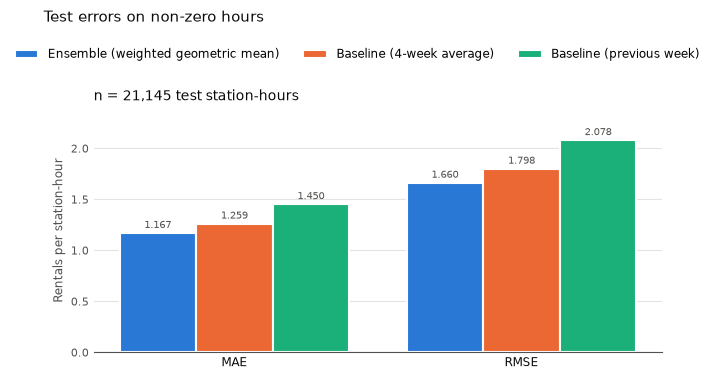

,MAE,RMSE
Ensemble (weighted geometric mean),1.1675,1.6598
Baseline (4-week average),1.2593,1.7977
Baseline (previous week),1.4498,2.0778


In [7]:
subsets = {'': subset_df[NUM_RENTALS] > 0}
table = subset_results(subsets, 'Non-zero hours')
plot_subsets(table, subsets, 'Test errors on non-zero hours', 'subset_non_zero_hours.png')
table

### 4.3 Busiest stations

Top 10 stations: 14,580 of 74,358 test station-hours. Ensemble vs 4-week average: MAE 8.2% lower, RMSE 10.5% lower


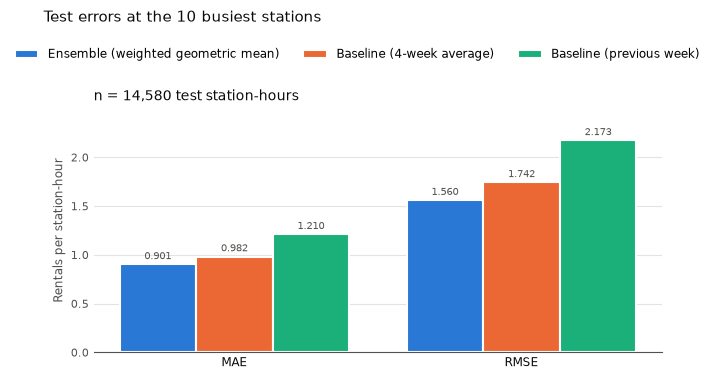

,MAE,RMSE
Ensemble (weighted geometric mean),0.9015,1.5596
Baseline (4-week average),0.9820,1.7425
Baseline (previous week),1.2099,2.1728


In [8]:
subsets = {'': is_top10}
table = subset_results(subsets, 'Top 10 stations')
plot_subsets(table, subsets, 'Test errors at the 10 busiest stations', 'subset_busiest_stations.png')
table

### 4.4 Peak hours

Peak hours (weekday peaks): 13,770 of 74,358 test station-hours. Ensemble vs 4-week average: MAE 0.2% lower, RMSE 5.5% lower
Peak hours (weekend peaks): 4,896 of 74,358 test station-hours. Ensemble vs 4-week average: MAE 14.5% lower, RMSE 17.2% lower


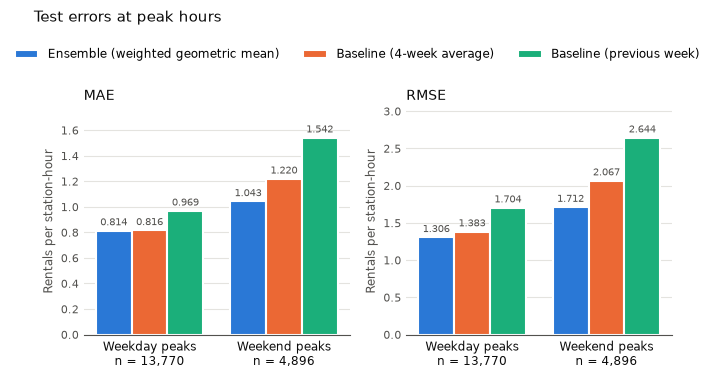

,Weekday peaks: MAE,Weekday peaks: RMSE,Weekend peaks: MAE,Weekend peaks: RMSE
Ensemble (weighted geometric mean),0.8144,1.3063,1.0426,1.7119
Baseline (4-week average),0.8160,1.3830,1.2197,2.0675
Baseline (previous week),0.9691,1.7044,1.5418,2.6445


In [9]:
subsets = {'Weekday peaks: ': is_weekday_peak, 'Weekend peaks: ': is_weekend_peak}
table = subset_results(subsets, 'Peak hours')
plot_subsets(table, subsets, 'Test errors at peak hours', 'subset_peak_hours.png')
table